# Modeling a Galaxy with The Tractor

This notebook demonstrates how The Tractor (Lang et al. 2016) works on a single source in Euclid
VIS and NISP images. The Tractor measures sources with a generative model: it takes a parameterized
source model together with the image's point-spread function (PSF), noise, sky level, and zeropoint,
renders the predicted image, and adjusts the parameters until the model best matches the data (for
independent Gaussian noise, minimum chi-squared).

Sections 1 to 4 fit the galaxy's flux and shape on VIS. Sections 5 and 6 then do forced photometry:
the VIS model is held fixed in position and shape, rendered with the NISP H PSF, and refitted only
for its flux. Every band is thereby measured with the same source model, even where a source is
faint, blended, or undetected. The notebooks that follow repeat these two steps for every source in
a field and carry the VIS models to other instruments.

## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import euclid_phot as ep
from tractor import (Image, PixelizedPSF, ConstantSky, LinearPhotoCal, NullWCS,
                     PixPos, Flux, EllipseE, ExpGalaxy, Tractor)

# Coordinates of the galaxy (degrees) and the side of the square cutout (arcsec).
# Any position inside the Euclid footprint works; the image is fetched from IRSA.
RA, DEC = 269.45284, 67.28963
SIZE = 6.0

## 1. Load the VIS cutout and its PSF

``fetch_cutout`` reads a ``SIZE`` arcsec box out of the MER VIS mosaic together with the matching
RMS map, which gives the noise in each pixel.

MER provides a PSF model evaluated at the position of every catalog source, the CATALOG-PSF
product. ``extract_catalog_psf`` returns the stamps around the target, and ``get_psf_for_source``
selects the one closest to the galaxy.

The cutout and the PSF stamps are downloaded from IRSA on first use and read from the local cache
afterwards.

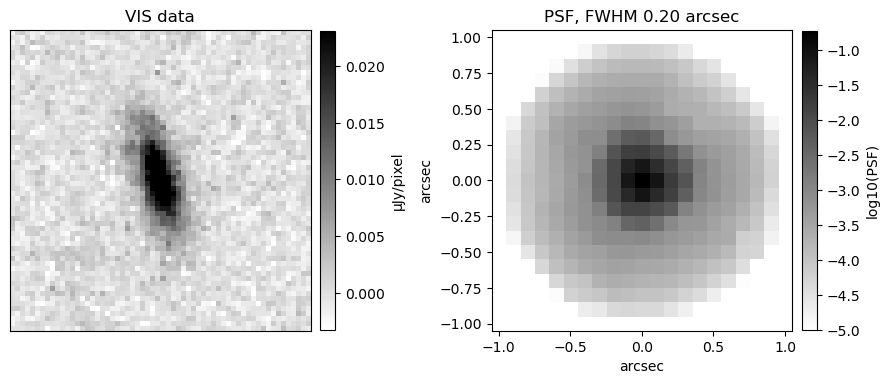

In [2]:
vis = ep.fetch_cutout("VIS", RA, DEC, SIZE)
psf_data = ep.extract_catalog_psf("VIS", RA, DEC, tile_id=vis.header.get("MERTILE"))
psf, psf_fwhm, _ = ep.get_psf_for_source(psf_data, RA, DEC)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4))
ep.viz.show_cutout(vis, ax=ax1, title="VIS data")

psf_half = psf.shape[0] / 2 * vis.pixel_scale_arcsec
ax2.imshow(np.log10(np.clip(psf, 1e-5, None)), origin="lower", cmap="gray_r",
           extent=[-psf_half, psf_half, -psf_half, psf_half])
ep.viz.add_colorbar(ax2, label="log10(PSF)")
ax2.set_title(f"PSF, FWHM {psf_fwhm:.2f} arcsec")
ax2.set_xlabel("arcsec")
ax2.set_ylabel("arcsec")
plt.tight_layout()
plt.show()


*Left: the VIS cutout around the galaxy. Right: the MER PSF model at its position, on a log
stretch, with its FWHM in the title.*

## 2. Construct the Tractor image and the source model

The fit is specified by three objects.

An ``Image`` contains the pixel data, the inverse variance, the PSF, the sky model, and the
magnitude zeropoint, taken from the ``MAGZERO`` header keyword. Converting it to image units per
microJansky and passing that to ``LinearPhotoCal`` makes the fitted amplitude a flux in microJansky.

We choose an exponential profile, ``ExpGalaxy``, as the source model: this galaxy is a disk, and
it is the simplest resolved profile The Tractor offers. Later notebooks instead select the profile per
source by comparing several. The model is parameterized by position, flux, and shape. The shape is
stored as a half-light radius and two ellipticity components, equivalently as an axis ratio and a
position angle. The position is held fixed at the catalog coordinate, which
is the sense in which the photometry is forced. The remaining parameters are initialized away from
the expected solution, at 2 microJansky, circular, and compact.

The ``Tractor`` object combines the image and the source model and performs the optimization.

In [3]:
data = vis.data
invvar = 1.0 / vis.rms**2
x, y = vis.wcs.all_world2pix(RA, DEC, 0)

counts_per_ujy = 10 ** (0.4 * (vis.header["MAGZERO"] - 23.9))
tim = Image(data=data, invvar=invvar, psf=PixelizedPSF(psf),
            wcs=NullWCS(pixscale=vis.pixel_scale_arcsec),
            sky=ConstantSky(0.0), photocal=LinearPhotoCal(counts_per_ujy))

gal = ExpGalaxy(PixPos(float(x), float(y)), Flux(2.0), EllipseE.fromRAbPhi(0.15, 1.0, 0.0))
gal.freezeParam("pos")

tractor = Tractor([tim], [gal])
tractor.freezeParam("images")

## 3. Optimize the model against the pixels

Each call to ``optimize`` performs one step. The Tractor computes the derivative of the predicted
image with respect to each free parameter, solves the resulting linear least-squares problem for the
direction that most reduces chi-squared, evaluates a set of step lengths along that direction, and
retains the best step. Four parameters vary here: the flux and the three shape parameters.

The loop below prints the parameters after each step and stops when the gain in
log-likelihood is below `1e-3`, or after 30 steps. This is a numerical stopping
criterion; it does not establish that the profile fully describes the galaxy.

In [4]:
for step in range(30):
    dlnp, _, _ = tractor.optimize()
    print(f"step {step + 1}: flux {gal.brightness.getValue():.2f} uJy, "
          f"re {gal.shape.re:.2f} arcsec, b/a {gal.shape.ab:.2f}")
    if dlnp < 1e-3:
        break

step 1: flux 2.05 uJy, re 0.44 arcsec, b/a 0.11
step 2: flux 2.72 uJy, re 0.73 arcsec, b/a 0.33
step 3: flux 4.07 uJy, re 0.98 arcsec, b/a 0.27
step 4: flux 4.08 uJy, re 0.91 arcsec, b/a 0.30
step 5: flux 4.10 uJy, re 0.92 arcsec, b/a 0.30
step 6: flux 4.10 uJy, re 0.92 arcsec, b/a 0.30
step 7: flux 4.10 uJy, re 0.92 arcsec, b/a 0.30


## 4. Data, model, and residual

Below we plot the galaxy, the best-fit model, and their residual. The third panel is the chi image:
the residual, data minus model, divided by the noise sigma of each pixel. This is the quantity
returned by ``Tractor.getChiImage``, and its sum of squares is the chi-squared minimized by the fit.
Coherent residual structure can reveal limitations of the profile, PSF, or background even after
numerical convergence.

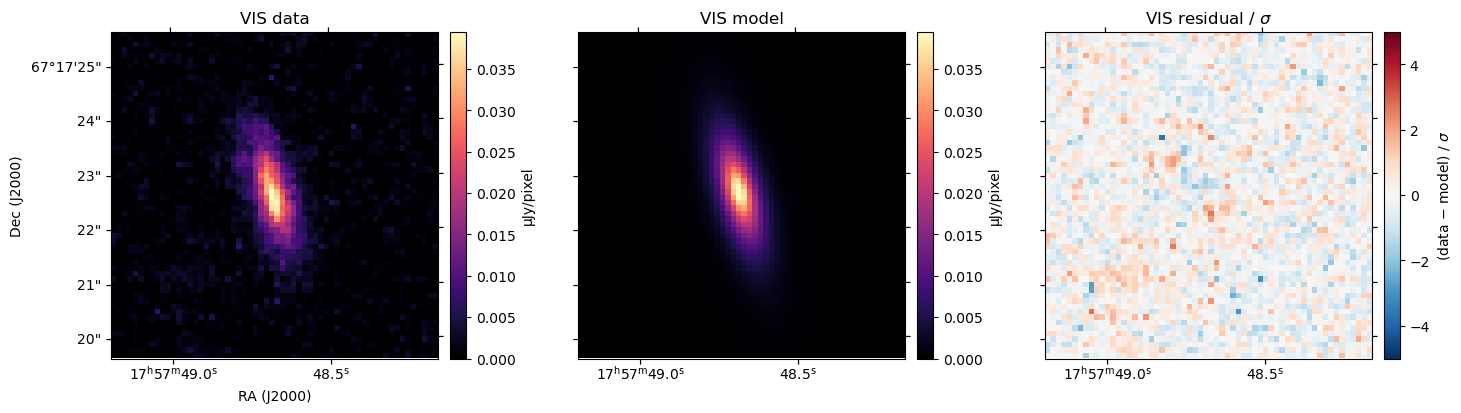

In [5]:
model = tractor.getModelImage(0)
chi = (data - model) * np.sqrt(invvar)
UJY = ep.viz.ujy_per_unit(vis)  # microJansky per image unit, from MAGZERO

vmax = 0.85 * data.max() * UJY
panels = [(data * UJY, "VIS data", "µJy/pixel", dict(cmap="magma", vmin=0, vmax=vmax)),
          (model * UJY, "VIS model", "µJy/pixel", dict(cmap="magma", vmin=0, vmax=vmax)),
          (chi, r"VIS residual / $\sigma$", r"(data $-$ model) / $\sigma$", dict(cmap="RdBu_r", vmin=-5, vmax=5))]

fig = plt.figure(figsize=(15, 4.2))
for k, (img, title, unit, kw) in enumerate(panels):
    ax = fig.add_subplot(1, 3, k + 1, projection=vis.wcs)
    im = ax.imshow(img, origin="lower", **kw)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label=unit)
    ax.set_title(title)
    ax.coords[0].set_ticks(number=3)
    if k == 0:
        ax.set_xlabel("RA (J2000)")
        ax.set_ylabel("Dec (J2000)")
    else:
        ax.coords[0].set_axislabel("")
        ax.coords[1].set_axislabel("")
        ax.coords[1].set_ticklabel_visible(False)
plt.tight_layout()
plt.show()

*Left: the VIS data. Center: the fitted exponential model. Right: the residual divided by the
pixel noise, on a scale of plus or minus five sigma.*

## 5. Forced photometry in NISP H

This is the step the other notebooks repeat for every source and band. The galaxy's position and
shape were measured on VIS, whose PSF is about 0.2 arcsec wide. In the NISP mosaics the PSF is
about 0.5 arcsec, so the same galaxy is more blurred and its shape is harder to measure, most of all
for faint or blended sources. Forced photometry takes the VIS model, keeps its position and shape,
renders it with the H-band PSF, and fits only its flux.

Only the image changes: the H pixels, their noise, the H PSF at this position, and the H zeropoint.
MER resamples every band onto the same 0.1 arcsec grid, so the galaxy falls on the same pixel in
both cutouts. The source is a copy of the VIS galaxy with the fitted shape and a new flux, and
``freezeAllBut("brightness")`` leaves the flux as its only free parameter. To measure Y or J
instead, change ``NISP_BAND``.

In [6]:
NISP_BAND = "H"

nisp = ep.fetch_cutout(NISP_BAND, RA, DEC, SIZE)
psf_nisp_data = ep.extract_catalog_psf(NISP_BAND, RA, DEC, tile_id=nisp.header.get("MERTILE"))
psf_nisp, psf_nisp_fwhm, _ = ep.get_psf_for_source(psf_nisp_data, RA, DEC)
print(f"{NISP_BAND} PSF FWHM {psf_nisp_fwhm:.2f} arcsec (VIS {psf_fwhm:.2f} arcsec)")

x_nisp, y_nisp = nisp.wcs.all_world2pix(RA, DEC, 0)
counts_per_ujy_nisp = 10 ** (0.4 * (nisp.header["MAGZERO"] - 23.9))
tim_nisp = Image(data=nisp.data, invvar=1.0 / nisp.rms**2, psf=PixelizedPSF(psf_nisp),
                 wcs=NullWCS(pixscale=nisp.pixel_scale_arcsec),
                 sky=ConstantSky(0.0), photocal=LinearPhotoCal(counts_per_ujy_nisp))

# The VIS model: same position and shape, a new flux, and nothing else free.
gal_nisp = ExpGalaxy(PixPos(float(x_nisp), float(y_nisp)), Flux(1.0), gal.shape.copy())
gal_nisp.freezeAllBut("brightness")

tractor_nisp = Tractor([tim_nisp], [gal_nisp])
tractor_nisp.freezeParam("images")
print("free parameters:", tractor_nisp.getParamNames())

H PSF FWHM 0.55 arcsec (VIS 0.20 arcsec)
free parameters: ['catalog.source0.brightness.Flux']


With only the flux free, the model image is the fixed profile times one number, so chi-squared is
quadratic in the flux and a single linear solve reaches its minimum; no iteration is needed.
``optimize_forced_photometry`` performs that solve and, with ``variance=True``, also returns the
inverse variance of the flux, from which its 1-sigma error follows. That error describes the pixel
noise only: it assumes the VIS shape is also correct in H.

In [7]:
fit = tractor_nisp.optimize_forced_photometry(variance=True)
flux_vis = gal.brightness.getValue()
flux_nisp = gal_nisp.brightness.getValue()
err_nisp = 1.0 / np.sqrt(fit.IV[0])

print(f"VIS flux (shape free): {flux_vis:.2f} uJy")
print(f"{NISP_BAND} flux (forced):     {flux_nisp:.2f} +/- {err_nisp:.2f} uJy")
print(f"VIS - {NISP_BAND} colour:         {-2.5 * np.log10(flux_vis / flux_nisp):.2f} mag")

VIS flux (shape free): 4.10 uJy
H flux (forced):     9.53 +/- 0.22 uJy
VIS - H colour:         0.92 mag


## 6. H data, model, and residual

The VIS image is shown again for comparison with the H image: the same galaxy, more blurred by the
wider H PSF. The H model is the VIS profile rendered with that PSF and scaled by the fitted flux.
As in section 4, the last panel is the residual divided by the pixel noise.

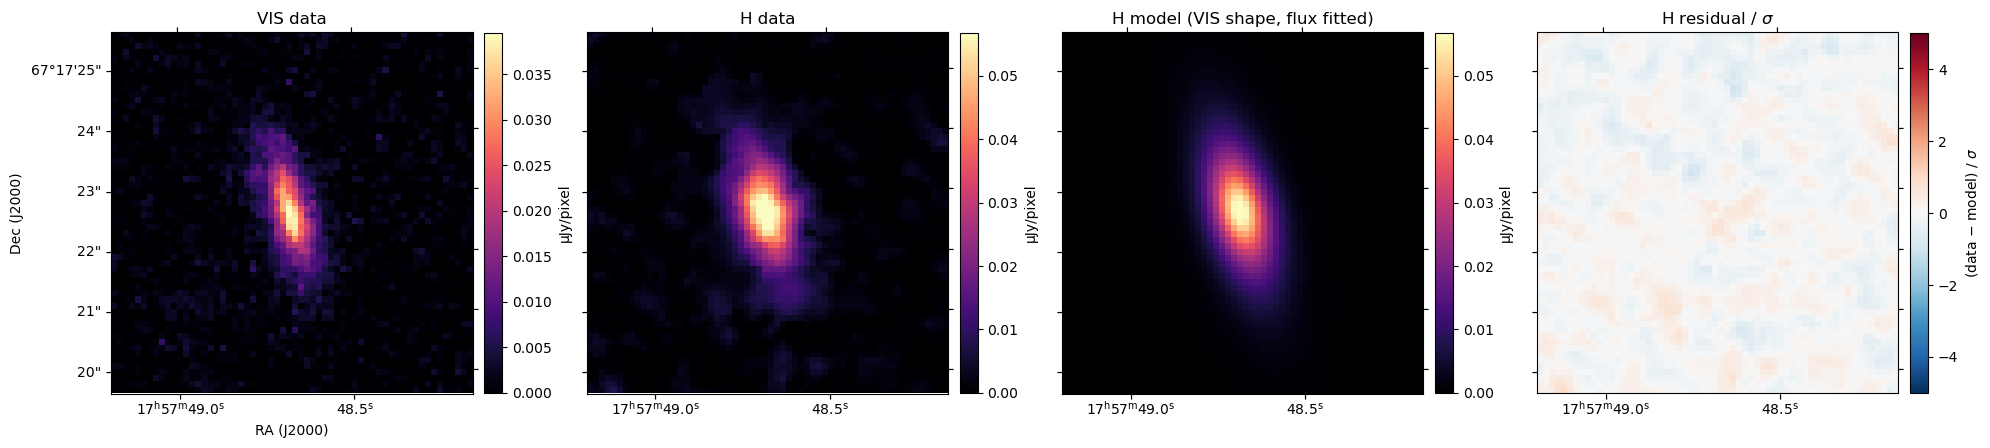

std of residual / sigma: VIS 0.68, H 0.24


In [8]:
model_nisp = tractor_nisp.getModelImage(0)
chi_nisp = (nisp.data - model_nisp) * np.sqrt(tim_nisp.getInvvar())
UJY_NISP = ep.viz.ujy_per_unit(nisp)

vmax_nisp = 0.85 * nisp.data.max() * UJY_NISP
panels = [(data * UJY, "VIS data", "µJy/pixel", dict(cmap="magma", vmin=0, vmax=vmax)),
          (nisp.data * UJY_NISP, f"{NISP_BAND} data", "µJy/pixel",
           dict(cmap="magma", vmin=0, vmax=vmax_nisp)),
          (model_nisp * UJY_NISP, f"{NISP_BAND} model (VIS shape, flux fitted)", "µJy/pixel",
           dict(cmap="magma", vmin=0, vmax=vmax_nisp)),
          (chi_nisp, rf"{NISP_BAND} residual / $\sigma$", r"(data $-$ model) / $\sigma$",
           dict(cmap="RdBu_r", vmin=-5, vmax=5))]

fig = plt.figure(figsize=(20, 4.6))
for k, (img, title, unit, kw) in enumerate(panels):
    ax = fig.add_subplot(1, 4, k + 1, projection=nisp.wcs)
    im = ax.imshow(img, origin="lower", **kw)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label=unit)
    ax.set_title(title, fontsize=12)
    ax.coords[0].set_ticks(number=3)
    if k == 0:
        ax.set_xlabel("RA (J2000)")
        ax.set_ylabel("Dec (J2000)")
    else:
        ax.coords[0].set_axislabel("")
        ax.coords[1].set_axislabel("")
        ax.coords[1].set_ticklabel_visible(False)
plt.tight_layout()
plt.show()
print(f"std of residual / sigma: VIS {np.std(chi):.2f}, {NISP_BAND} {np.std(chi_nisp):.2f}")

*From left: the VIS data, the H data, the VIS model rendered with the H PSF at the fitted flux,
and the H residual divided by the pixel noise. The VIS and H data have separate brightness scales.*

The H residual looks fainter than the VIS one because it is. The NISP detectors have 0.3 arcsec
pixels, and MER resamples them onto the 0.1 arcsec grid. Resampling spreads the noise of each
detector pixel over several mosaic pixels, so neighbouring pixels are correlated and the
pixel-to-pixel scatter is below the RMS map; the printed standard deviations show the effect in
both bands, and it is much stronger in H, whose native pixels are three times larger. The
formal flux error assumes independent pixels and is only approximate for that reason;
[notebook 01](01_nisp_forced_photometry.ipynb) (section 12) calibrates it with fits at empty
positions.

### What holding the shape fixed changes

For comparison, the cell below fits the shape freely on the H image, as section 3 did on VIS.

In [9]:
gal_free = ExpGalaxy(PixPos(float(x_nisp), float(y_nisp)), Flux(1.0),
                     EllipseE.fromRAbPhi(0.15, 1.0, 0.0))
gal_free.freezeParam("pos")
tractor_free = Tractor([tim_nisp], [gal_free])
tractor_free.freezeParam("images")
for step in range(50):
    dlnp, _, _ = tractor_free.optimize()
    if dlnp < 1e-3:
        break

print(f"{'':>22s} {'flux (uJy)':>11s} {'re (arcsec)':>12s} {'b/a':>6s}")
for label, g in ((f"{NISP_BAND}, VIS shape (forced)", gal_nisp), (f"{NISP_BAND}, shape free", gal_free)):
    print(f"{label:>22s} {g.brightness.getValue():11.2f} {g.shape.re:12.2f} {g.shape.ab:6.2f}")

                        flux (uJy)  re (arcsec)    b/a
 H, VIS shape (forced)        9.53         0.92   0.30
         H, shape free        9.07         0.81   0.32


For this bright, isolated galaxy the two H fits agree to within several percent. For a faint or
blended source a free fit in H is poorly constrained, and colours built from fits made separately
in each band compare different models of the light. The forced fit uses one model in every band,
so the colour compares the same light in VIS and H. The price is the assumption that the galaxy
has the same shape from 0.7 to 1.8 microns: colour gradients, such as a red bulge in a blue disk,
break it and leave a structured residual.

[Notebook 01](01_nisp_forced_photometry.ipynb) applies both steps to every MER source in a
200 arcsec field: choosing and fitting a model for each source on VIS, fitting neighbours together,
and then forcing the fluxes in Y, J, and H.